# Q1: NumPy – Academic Performance Analysis
**Aim:** To analyse the marks of 50 students in five subjects using NumPy.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Load dataset (create it if the file is not given)

In [2]:
subjects = ["Python", "Statistics", "Machine_Learning", "Data_Mining", "Research_Methods"]
try:
    df = pd.read_csv("01_NumPy_Academic_Performance.csv")
except FileNotFoundError:
    np.random.seed(42)
    ability = np.random.normal(72, 10, 50)
    df = pd.DataFrame({"Student_ID": [f"S{i:02d}" for i in range(1, 51)]})
    for s in subjects:
        df[s] = np.clip(ability + np.random.normal(0, 8, 50), 35, 100).round()
    df.loc[0, subjects] = [92, 95, 55, 90, 88]
df.head()

,Student_ID,Python,Statistics,Machine_Learning,Data_Mining,Research_Methods
0,S01,92.0,95.0,55.0,90.0,88.0
1,S02,68.0,67.0,73.0,75.0,78.0
2,S03,73.0,76.0,73.0,87.0,95.0
3,S04,92.0,81.0,89.0,96.0,95.0
4,S05,78.0,68.0,72.0,59.0,58.0


### 1. Mean, median, SD, variance, min, max (subject-wise)

In [3]:
X = df[subjects].values
pd.DataFrame({"Mean": X.mean(axis=0), "Median": np.median(X, axis=0),
              "Std": X.std(axis=0, ddof=1), "Variance": X.var(axis=0, ddof=1),
              "Min": X.min(axis=0), "Max": X.max(axis=0)}, index=subjects).round(2)

,Mean,Median,Std,Variance,Min,Max
Python,70.08,70.0,12.59,158.61,43.0,93.0
Statistics,69.96,69.0,11.96,143.06,47.0,100.0
Machine_Learning,69.92,69.5,12.36,152.73,45.0,100.0
Data_Mining,70.90,72.0,14.32,204.99,45.0,100.0
Research_Methods,70.04,67.0,14.31,204.65,44.0,98.0


### 2. Coefficient of variation, IQR and Z-scores

In [4]:
mean, std = X.mean(axis=0), X.std(axis=0, ddof=1)
q1, q3 = np.percentile(X, [25, 75], axis=0)
pd.DataFrame({"CV_%": std / mean * 100, "Q1": q1, "Q3": q3, "IQR": q3 - q1}, index=subjects).round(2)

,CV_%,Q1,Q3,IQR
Python,17.97,61.00,80.00,19.00
Statistics,17.10,63.25,75.75,12.50
Machine_Learning,17.67,61.00,79.50,18.50
Data_Mining,20.19,59.00,80.25,21.25
Research_Methods,20.42,59.00,78.00,19.00


In [5]:
Z = (X - mean) / std
pd.DataFrame(Z, columns=subjects).round(2).head()

,Python,Statistics,Machine_Learning,Data_Mining,Research_Methods
0,1.74,2.09,-1.21,1.33,1.26
1,-0.17,-0.25,0.25,0.29,0.56
2,0.23,0.50,0.25,1.12,1.74
3,1.74,0.92,1.54,1.75,1.74
4,0.63,-0.16,0.17,-0.83,-0.84


### 3. Average > 80 but below 60 in at least one subject

In [6]:
avg = X.mean(axis=1)
df[(avg > 80) & (X < 60).any(axis=1)]

,Student_ID,Python,Statistics,Machine_Learning,Data_Mining,Research_Methods
0,S01,92.0,95.0,55.0,90.0,88.0


### 4. Z-score below −1 in at least two subjects

In [7]:
df[(Z < -1).sum(axis=1) >= 2]

,Student_ID,Python,Statistics,Machine_Learning,Data_Mining,Research_Methods
13,S14,43.0,73.0,46.0,58.0,45.0
14,S15,61.0,53.0,62.0,52.0,53.0
19,S20,53.0,64.0,52.0,59.0,59.0
23,S24,70.0,47.0,60.0,45.0,58.0
33,S34,57.0,65.0,65.0,56.0,52.0
35,S36,56.0,72.0,66.0,65.0,44.0
37,S38,55.0,50.0,52.0,54.0,57.0
38,S39,54.0,65.0,52.0,53.0,61.0
44,S45,54.0,59.0,59.0,48.0,60.0
49,S50,52.0,57.0,45.0,58.0,59.0


### 5. Min-Max and Z-score normalization

In [8]:
minmax = (X - X.min(axis=0)) / (X.max(axis=0) - X.min(axis=0))
print("Min-Max -> min:", minmax.min(axis=0).round(2), " max:", minmax.max(axis=0).round(2))
print("Z-score -> mean:", Z.mean(axis=0).round(2), " std:", Z.std(axis=0, ddof=1).round(2))
pd.DataFrame({"Python_Raw": X[:5, 0], "Python_MinMax": minmax[:5, 0].round(3), "Python_Z": Z[:5, 0].round(3)})

Min-Max -> min: [0. 0. 0. 0. 0.]  max: [1. 1. 1. 1. 1.]
Z-score -> mean: [ 0.  0. -0. -0. -0.]  std: [1. 1. 1. 1. 1.]


,Python_Raw,Python_MinMax,Python_Z
0,92.0,0.98,1.741
1,68.0,0.50,-0.165
2,73.0,0.60,0.232
3,92.0,0.98,1.741
4,78.0,0.70,0.629


Min-Max rescales every subject to the range 0–1. Z-score centres each subject at mean 0 with SD 1, so it can be negative. Both keep the students' order the same; Z-score is less affected by extreme values.

### 6. Weighted academic performance index

In [9]:
w = np.array([0.30, 0.25, 0.20, 0.15, 0.10])
wpi = X @ w
df["Average"] = avg.round(2)
df["WPI"] = wpi.round(2)
df[["Student_ID", "Average", "WPI"]].head()

,Student_ID,Average,WPI
0,S01,84.0,84.65
1,S02,72.2,70.80
2,S03,80.8,78.05
3,S04,90.6,89.55
4,S05,67.0,69.45


### 7. Ranking by average and by WPI

In [10]:
df["Rank_Avg"] = df["Average"].rank(ascending=False, method="min").astype(int)
df["Rank_WPI"] = df["WPI"].rank(ascending=False, method="min").astype(int)
df["Rank_Diff"] = (df["Rank_Avg"] - df["Rank_WPI"]).abs()
df[df["Rank_Diff"] >= 5].sort_values("Rank_Diff", ascending=False)

,Student_ID,Python,Statistics,Machine_Learning,Data_Mining,Research_Methods,Average,WPI,Rank_Avg,Rank_WPI,Rank_Diff
2,S03,73.0,76.0,73.0,87.0,95.0,80.8,78.05,9,14,5
4,S05,78.0,68.0,72.0,59.0,58.0,67.0,69.45,30,25,5


Students listed above move 5 or more places when the subjects are weighted (rank difference ≥ 5 is taken as significant).

### 8. Correlation matrix and heatmap

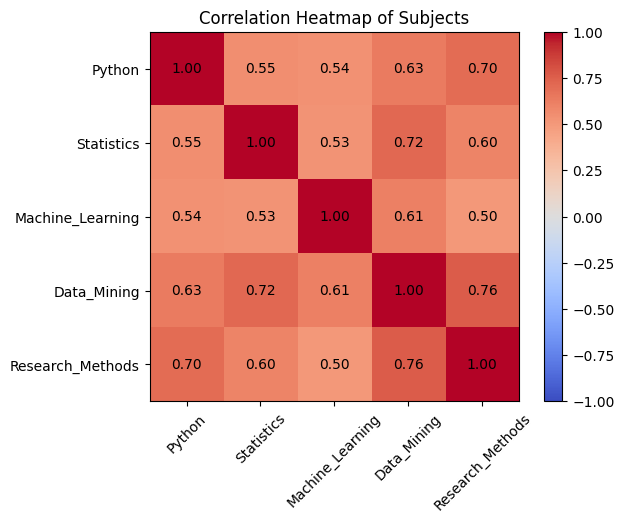

In [11]:
corr = np.corrcoef(X, rowvar=False)
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(5), subjects, rotation=45)
plt.yticks(range(5), subjects)
for i in range(5):
    for j in range(5):
        plt.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center")
plt.title("Correlation Heatmap of Subjects")
plt.show()

**Result:** Descriptive statistics, normalization, weighted index, rankings and correlations of student marks were computed successfully using NumPy.